In [54]:
#imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_lyapunov
from scipy.integrate import solve_ivp

Controllability Gramian P:
 [[2.         0.66666667]
 [0.66666667 0.25      ]]
Observability Gramian Q:
 [[0.5  1.  ]
 [1.   2.25]]
Hankel values: [1.70100948+0.j 0.04899052+0.j]
Matrix Sigma: [1.70100948 0.04899052]
Transformation matrix T:
 [[-1.07300046 -0.92123288]
 [-0.37609175  0.4380506 ]]
Balanced Controllability Gramian Ptilde:
 [[ 1.70100948e+00 -9.67965828e-17]
 [-8.34032725e-17  4.89905166e-02]]
Balanced Observability Gramian Qtilde:
 [[ 1.70100948e+00 -6.42604428e-16]
 [-6.09117394e-16  4.89905166e-02]]


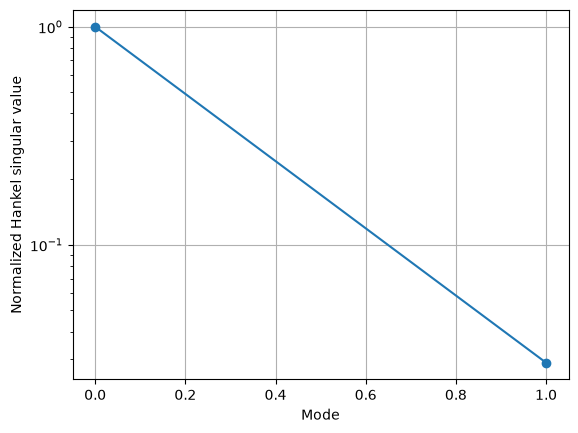

In [59]:
#n=2 example
A = np.array([
        [-1.0, 0.0],
        [0.0, -2.0]
    ])
B = np.array([[2.0], [1.0]])
C = np.array([[1.0, 3.0]])
D = np.array([[0.0]])

#compute gramians
# Solve A*P + P*A^T = -B*B^T for Controllability Gramian (P)
P = solve_continuous_lyapunov(A, -B @ B.T)

# Solve A^T*Q + Q*A = -C^T*C for Observability Gramian (Q)
Q = solve_continuous_lyapunov(A.T, -C.T @ C)

#find Hankel singular values
PQ = P @ Q
Hankel_SVs = np.sqrt(np.linalg.eigvals(PQ))

#cholesky decomposition
R = np.linalg.cholesky(P)
S = np.linalg.cholesky(Q)

#SVD of S^T R
U, Sigma, V_T = np.linalg.svd(S.T @ R)

#balancing transformation
T = R @ V_T.T @ np.diag(1.0 / np.sqrt(Sigma))
T_inv = np.diag(1.0 / np.sqrt(Sigma)) @ U.T @ S.T

Ptilde = T_inv @ P @ T_inv.T
Qtilde = T.T @ Q @ T

print("Controllability Gramian P:\n", P)
print("Observability Gramian Q:\n", Q)
print("Hankel values:", Hankel_SVs)
print("Matrix Sigma:", Sigma)
print("Transformation matrix T:\n", T)
print("Balanced Controllability Gramian Ptilde:\n", Ptilde)
print("Balanced Observability Gramian Qtilde:\n", Qtilde)

#normalized Hankel singular values plot
plt.semilogy(Sigma/Sigma[0],'o-')
plt.xlabel('Mode')
plt.ylabel('Normalized Hankel singular value')
plt.grid()
plt.show()

In [60]:
#find r
tau = 0.1 #10% error
# 1. Calculate all tail sums for r = 1 to n (including 0 at the end for r = n)
tail_sums = np.append(np.cumsum(Sigma[:0:-1])[::-1], 0)
# 2. Find the index of the first True condition (+1 converts 0-based index to 1-based r)
r = np.argmax((2 * tail_sums / Sigma[0]) < tau) + 1
print("r for 10% error:", r)

#Balanced realization
A_balanced = T_inv @ A @ T
B_balanced = T_inv @ B
C_balanced = C @ T
D_balanced = D

print("Balanced A:\n", A_balanced)
print("Balanced B:\n", B_balanced)
print("Balanced C:\n", C_balanced)
print("Balanced D:\n", D_balanced)


#Reduce the system to r states
A_reduced = A_balanced[:r, :r]
B_reduced = B_balanced[:r, :]
C_reduced = C_balanced[:, :r]
D_reduced = D_balanced

print("Reduced A:\n", A_reduced)
print("Reduced B:\n", B_reduced)
print("Reduced C:\n", C_reduced)
print("Reduced D:\n", D_reduced)

r for 10% error: 1
Balanced A:
 [[-1.42433501  0.49424165]
 [ 0.49424165 -1.57566499]]
Balanced B:
 [[-2.2012757 ]
 [ 0.39291893]]
Balanced C:
 [[-2.2012757   0.39291893]]
Balanced D:
 [[0.]]
Reduced A:
 [[-1.42433501]]
Reduced B:
 [[-2.2012757]]
Reduced C:
 [[-2.2012757]]
Reduced D:
 [[0.]]


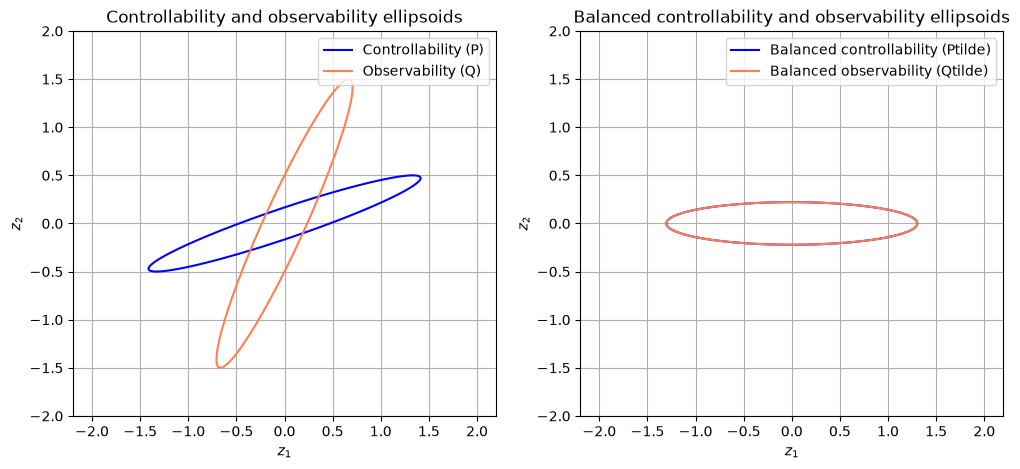

In [61]:
#create the plots

#plot original P and Q
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

x = np.linspace(-2, 2, 300)
y = np.linspace(-2, 2, 300)
X, Y = np.meshgrid(x, y)

Pinv = np.linalg.inv(P)
Qinv = np.linalg.inv(Q)

# Evaluate z.T @ inv(P) @ z and z.T @ inv(Q) @ z
ZP = Pinv[0, 0]*X**2 + 2*Pinv[0, 1]*X*Y + Pinv[1, 1]*Y**2
ZQ = Qinv[0, 0]*X**2 + 2*Qinv[0, 1]*X*Y + Qinv[1, 1]*Y**2

plt.contour(X, Y, ZP, levels=[1], colors="blue")
plt.contour(X, Y, ZQ, levels=[1], colors="coral")

plt.plot([], [], color="blue", label="Controllability (P)")
plt.plot([], [], color="coral", label="Observability (Q)")
plt.title("Controllability and observability ellipsoids")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")
plt.axis("equal")
plt.grid()
plt.legend()

#plot new Ptilde and Qtilde
plt.subplot(1, 2, 2)
Ptilde_inv = np.linalg.inv(Ptilde)
Qtilde_inv = np.linalg.inv(Qtilde)

# Evaluate z.T @ inv(P) @ z and z.T @ inv(Q) @ z
ZPtilde = Ptilde_inv[0, 0]*X**2 + 2*Ptilde_inv[0, 1]*X*Y + Ptilde_inv[1, 1]*Y**2
ZQtilde = Qtilde_inv[0, 0]*X**2 + 2*Qtilde_inv[0, 1]*X*Y + Qtilde_inv[1, 1]*Y**2

plt.contour(X, Y, ZPtilde, levels=[1], colors="blue")
plt.contour(X, Y, ZQtilde, levels=[1], colors="coral")

plt.plot([], [], color="blue", label="Balanced controllability (Ptilde)")
plt.plot([], [], color="coral", label="Balanced observability (Qtilde)")
plt.title("Balanced controllability and observability ellipsoids")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()


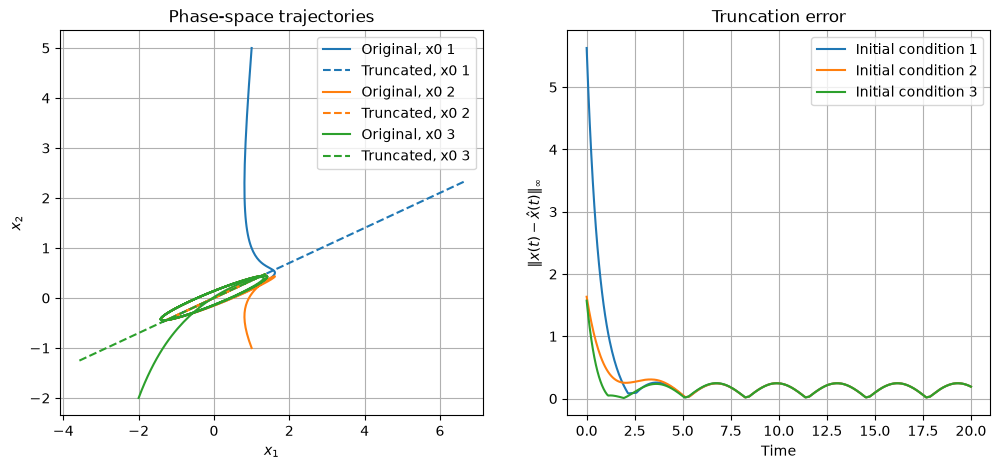

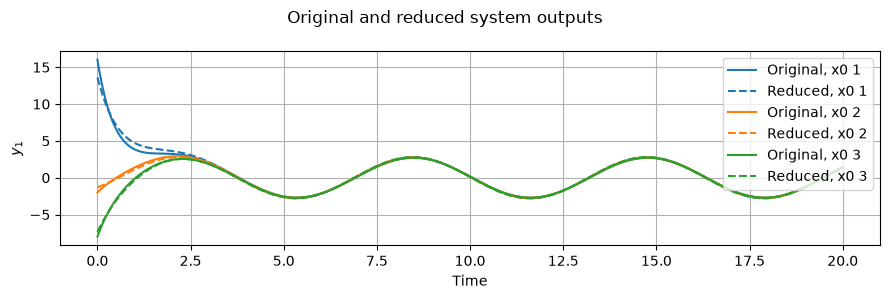

In [64]:
#plot whole system and reduced system
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

x0_list = [
    np.array([1.0, 5.0]),
    np.array([1.0, -1.0]),
    np.array([-2.0, -2.0])
]

t = np.linspace(0, 20, 500)
u = lambda time: np.sin(time)

# Calculate each full and reconstructed reduced trajectory once
trajectories = []
output_trajectories = []

for x0 in x0_list:
    xr0 = (T_inv @ x0)[:r]

    full = solve_ivp(
        lambda time, x: A @ x + B[:,0] * u(time),
        (t[0], t[-1]), x0, t_eval=t
    ).y.T

    reduced = solve_ivp(
        lambda time, xr: A_reduced @ xr + B_reduced[:,0] * u(time),
        (t[0], t[-1]), xr0, t_eval=t
    ).y.T

    approx = (T[:, :r] @ reduced.T).T
    trajectories.append((full, approx))
    output_full = (C @ full.T).T
    output_reduced = (C_reduced @ reduced.T).T
    output_trajectories.append((output_full, output_reduced))

# Phase-space plot: x1 versus x2
for i, (full, approx) in enumerate(trajectories):
    color = f"C{i}"
    plt.plot(full[:, 0], full[:, 1], color=color,
             label=f"Original, x0 {i + 1}")
    plt.plot(approx[:, 0], approx[:, 1], "--", color=color,
             label=f"Truncated, x0 {i + 1}")

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Phase-space trajectories")
plt.grid(True)
plt.legend()

# Error plot: distance between the original and truncated states
plt.subplot(1, 2, 2)

for i, (full, approx) in enumerate(trajectories):
    error = np.linalg.norm(full - approx, ord=np.inf, axis=1)
    plt.plot(t, error, label=f"Initial condition {i + 1}")

plt.xlabel("Time")
plt.ylabel(r"$\|x(t)-\hat{x}(t)\|_\infty$")
plt.title("Truncation error")
plt.grid(True)
plt.legend()
plt.show()

n_outputs = C.shape[0]
fig, axes = plt.subplots(
    n_outputs, 1, figsize=(9, 3 * n_outputs),
    sharex=True, squeeze=False
)

for j in range(n_outputs):
    ax = axes[j, 0]

    for i, (y_full, y_reduced) in enumerate(output_trajectories):
        color = f"C{i}"
        ax.plot(t, y_full[:, j], color=color,
                label=f"Original, x0 {i + 1}")
        ax.plot(t, y_reduced[:, j], "--", color=color,
                label=f"Reduced, x0 {i + 1}")

    ax.set_ylabel(f"$y_{j + 1}$")
    ax.grid(True)
    ax.legend()

axes[-1, 0].set_xlabel("Time")
fig.suptitle("Original and reduced system outputs")
fig.tight_layout()
plt.show()

Controllability Gramian P:
 [[2.         0.18181818 0.66666667]
 [0.18181818 0.05       0.16666667]
 [0.66666667 0.16666667 0.5625    ]]
Observability Gramian Q:
 [[0.5        0.18181818 0.11111111]
 [0.18181818 0.2        0.11111111]
 [0.11111111 0.11111111 0.0625    ]]
Hankel values: [1.12737967e+00+0.j 1.59599347e-01+0.j 5.20985522e-04+0.j]
Matrix Sigma: [1.12737967e+00 1.59599347e-01 5.20985522e-04]
Transformation matrix T:
 [[-1.31791861  0.51203125 -0.03024134]
 [-0.14466728 -0.40548925 -0.56093658]
 [-0.51871388 -1.27287343  1.05391135]]
Balanced Controllability Gramian Ptilde:
 [[ 1.12737967e+00  3.80573306e-17  6.39816872e-17]
 [ 4.70991539e-17  1.59599347e-01 -4.82955762e-17]
 [ 5.37141758e-17 -5.01228830e-17  5.20985522e-04]]
Balanced Observability Gramian Qtilde:
 [[ 1.12737967e+00 -1.59250137e-16 -2.50198073e-16]
 [-1.81706934e-16  1.59599347e-01 -2.71577967e-17]
 [-2.52369799e-16 -3.56496927e-17  5.20985522e-04]]


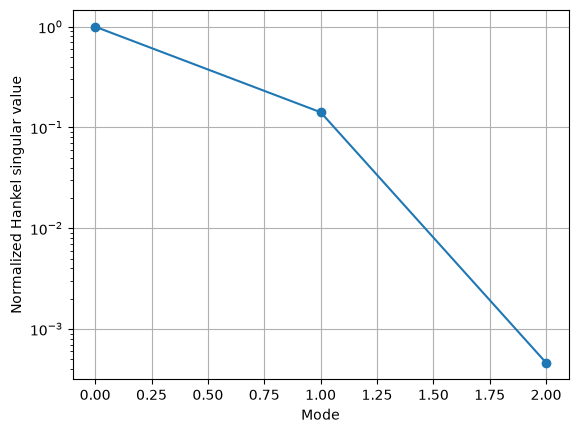

In [65]:
#define matrices 
A = np.array([
        [-1.0,  0.0,  0.0],
        [ 0.0, -10.0,  0.0,],
        [ 0.0,  0.0, -8.0,]
    ])
B = np.array([[2.0], [1.0], [3.0]])
C = np.array([[1.0, 2.0, 1.0]])
D = np.array([[0.0]])

#compute gramians
# Solve A*P + P*A^T = -B*B^T for Controllability Gramian (P)
P = solve_continuous_lyapunov(A, -B @ B.T)

# Solve A^T*Q + Q*A = -C^T*C for Observability Gramian (Q)
Q = solve_continuous_lyapunov(A.T, -C.T @ C)

#find Hankel singular values
PQ = P @ Q
Hankel_SVs = np.sqrt(np.linalg.eigvals(PQ))

#cholesky decomposition
R = np.linalg.cholesky(P)
S = np.linalg.cholesky(Q)

#SVD of S^T R
U, Sigma, V = np.linalg.svd(S.T @ R)

#balancing transformation
T = R @ V.T @ np.diag(1.0 / np.sqrt(Sigma))
T_inv = np.diag(1.0 / np.sqrt(Sigma)) @ U.T @ S.T

Ptilde = T_inv @ P @ T_inv.T
Qtilde = T.T @ Q @ T


print("Controllability Gramian P:\n", P)
print("Observability Gramian Q:\n", Q)
print("Hankel values:", Hankel_SVs)
print("Matrix Sigma:", Sigma)
print("Transformation matrix T:\n", T)
print("Balanced Controllability Gramian Ptilde:\n", Ptilde)
print("Balanced Observability Gramian Qtilde:\n", Qtilde)

#normalized Hankel singular values plot
plt.semilogy(Sigma/Sigma[0],'o-')
plt.xlabel('Mode')
plt.ylabel('Normalized Hankel singular value')
plt.grid()
plt.show()

In [66]:
#find r
tau = 0.1 #10% error
# 1. Calculate all tail sums for r = 1 to n (including 0 at the end for r = n)
tail_sums = np.append(np.cumsum(Sigma[:0:-1])[::-1], 0)
# 2. Find the index of the first True condition (+1 converts 0-based index to 1-based r)
r = np.argmax((2 * tail_sums / Sigma[0]) < tau) + 1
print("r for 10% error:", r)

#Balanced realization
A_balanced = T_inv @ A @ T
B_balanced = T_inv @ B
C_balanced = C @ T
D_balanced = D

print("Balanced A:\n", A_balanced)
print("Balanced B:\n", B_balanced)
print("Balanced C:\n", C_balanced)
print("Balanced D:\n", D_balanced)

#Reduce the system to r states
A_reduced = A_balanced[:r, :r]
B_reduced = B_balanced[:r, :]
C_reduced = C_balanced[:, :r]
D_reduced = D_balanced

print("Reduced A:\n", A_reduced)
print("Reduced B:\n", B_reduced)
print("Reduced C:\n", C_reduced)
print("Reduced D:\n", D_reduced)

r for 10% error: 2
Balanced A:
 [[-2.00453139 -2.59649842 -0.18510198]
 [-2.59649842 -7.74007012 -0.96401081]
 [-0.18510198 -0.96401081 -9.25539849]]
Balanced B:
 [[-2.12596704]
 [-1.57182069]
 [-0.09820314]]
Balanced C:
 [[-2.12596704 -1.57182069 -0.09820314]]
Balanced D:
 [[0.]]
Reduced A:
 [[-2.00453139 -2.59649842]
 [-2.59649842 -7.74007012]]
Reduced B:
 [[-2.12596704]
 [-1.57182069]]
Reduced C:
 [[-2.12596704 -1.57182069]]
Reduced D:
 [[0.]]


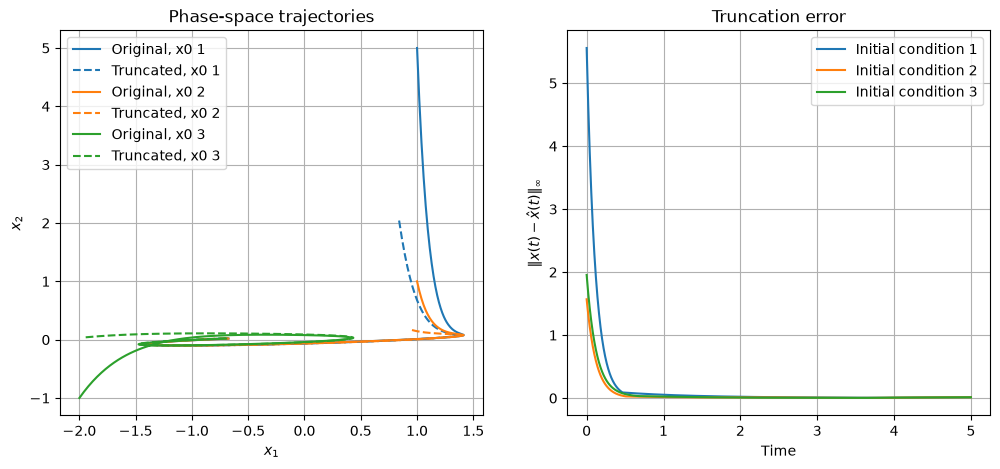

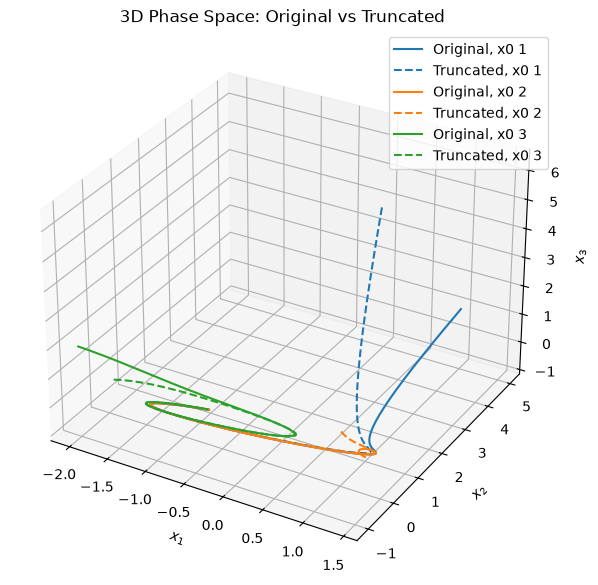

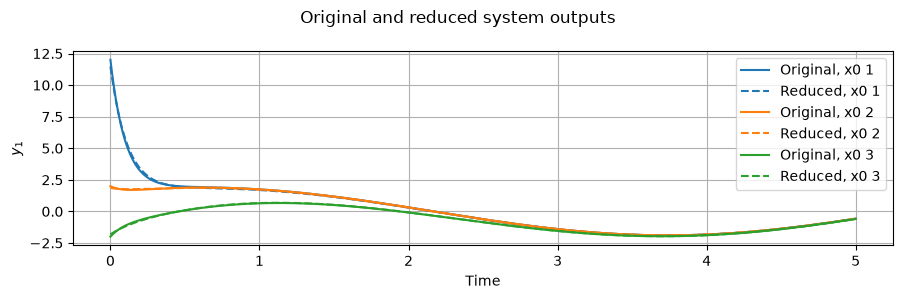

In [67]:
#plot whole system and reduced system
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

x0_list = [
    np.array([1.0, 5.0, 1.0]),
    np.array([1.0, 1.0, -1.0]),
    np.array([-2.0, -1.0, 2.0])
]

t = np.linspace(0, 5, 500)
u = lambda time: np.cos(time)

# Calculate each full and reconstructed reduced trajectory once
trajectories = []
output_trajectories = []

for x0 in x0_list:
    xr0 = (T_inv @ x0)[:r]

    full = solve_ivp(
        lambda time, x: A @ x+ B[:,0] * u(time),
        (t[0], t[-1]), x0, t_eval=t
    ).y.T

    reduced = solve_ivp(
        lambda time, xr: A_reduced @ xr + B_reduced[:,0] * u(time),
        (t[0], t[-1]), xr0, t_eval=t
    ).y.T

    approx = (T[:, :r] @ reduced.T).T
    trajectories.append((full, approx))    
    output_full = (C @ full.T).T
    output_reduced = (C_reduced @ reduced.T).T
    output_trajectories.append((output_full, output_reduced))


# Phase-space plot: x1 versus x2
for i, (full, approx) in enumerate(trajectories):
    color = f"C{i}"
    plt.plot(full[:, 0], full[:, 1], color=color,
             label=f"Original, x0 {i + 1}")
    plt.plot(approx[:, 0], approx[:, 1], "--", color=color,
             label=f"Truncated, x0 {i + 1}")

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Phase-space trajectories")
plt.grid(True)
plt.legend()

# Error plot: distance between the original and truncated states
plt.subplot(1, 2, 2)

for i, (full, approx) in enumerate(trajectories):
    error = np.linalg.norm(full - approx, ord=np.inf, axis=1)
    plt.plot(t, error, label=f"Initial condition {i + 1}")

plt.xlabel("Time")
plt.ylabel(r"$\|x(t)-\hat{x}(t)\|_\infty$")
plt.title("Truncation error")
plt.grid(True)
plt.legend()
plt.show() 

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

for i, (full, approx) in enumerate(trajectories):
    color = f"C{i}"
    ax.plot(full[:, 0], full[:, 1], full[:, 2],
            color=color, label=f"Original, x0 {i + 1}")
    ax.plot(approx[:, 0], approx[:, 1], approx[:, 2],
            "--", color=color, label=f"Truncated, x0 {i + 1}")

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.set_title("3D Phase Space: Original vs Truncated")
ax.legend()
plt.tight_layout()
plt.show()

n_outputs = C.shape[0]
fig, axes = plt.subplots(
    n_outputs, 1, figsize=(9, 3 * n_outputs),
    sharex=True, squeeze=False
)

for j in range(n_outputs):
    ax = axes[j, 0]

    for i, (y_full, y_reduced) in enumerate(output_trajectories):
        color = f"C{i}"
        ax.plot(t, y_full[:, j], color=color,
                label=f"Original, x0 {i + 1}")
        ax.plot(t, y_reduced[:, j], "--", color=color,
                label=f"Reduced, x0 {i + 1}")

    ax.set_ylabel(f"$y_{j + 1}$")
    ax.grid(True)
    ax.legend()

axes[-1, 0].set_xlabel("Time")
fig.suptitle("Original and reduced system outputs")
fig.tight_layout()
plt.show()